In [123]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print ("all modules imported successfully")

all modules imported successfully


In [124]:
df = pd.read_csv('tested.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875


In [125]:
print("First 5 Rows:")
display(df.head())

print("Dataset Shape:")
print(df.shape)

print("Dataset Information:")
df.info()

print("Statistical Summary:")
display(df.describe())

First 5 Rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875


Dataset Shape:
(418, 10)
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
dtypes: float64(2), int64(5), str(3)
memory usage: 32.8 KB
Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [126]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
PassengerId     0
Survived        0
Pclass          0
Name            0
Sex             0
Age            86
SibSp           0
Parch           0
Ticket          0
Fare            1
dtype: int64

Total Missing Values:
87


In [127]:
# Calculate missing values percentage
missing = df.isnull().sum()

missing_percentage = (missing / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percentage
})

display(missing_report)

,Missing Values,Missing Percentage
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,86,20.574163
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,1,0.239234


In [128]:
# Fill missing values using median
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# Check missing values again
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
dtype: int64

Total Missing Values: 0


In [129]:
print("duplicate rows:", df.duplicated().sum())

duplicate rows: 0


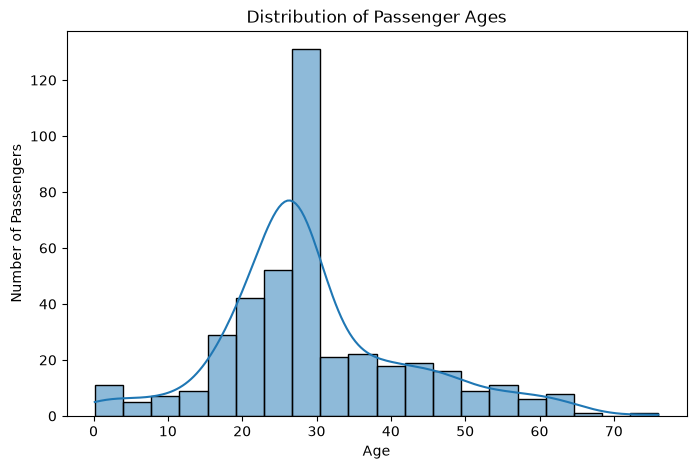

In [130]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

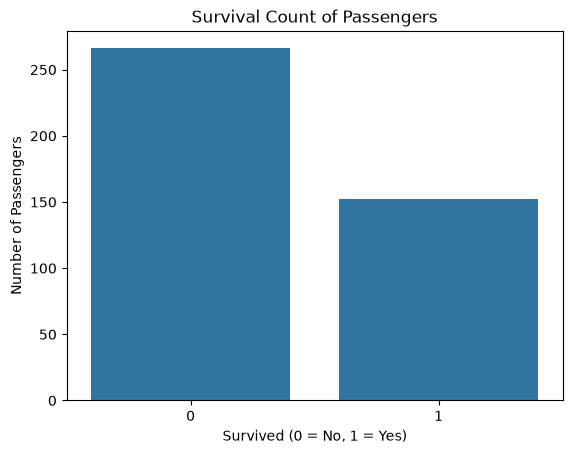

In [131]:
sns.countplot(data=df, x="Survived")

plt.title("Survival Count of Passengers")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

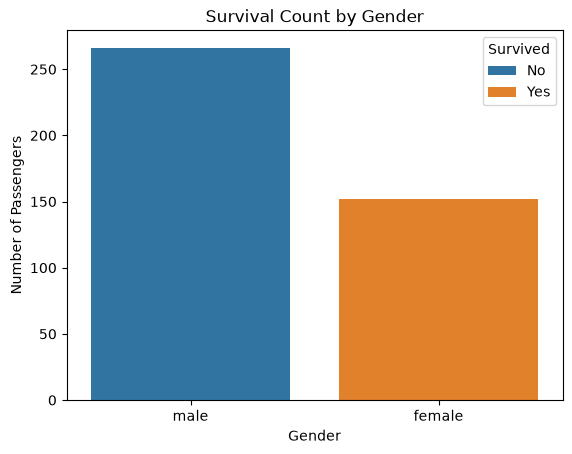

In [132]:
sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

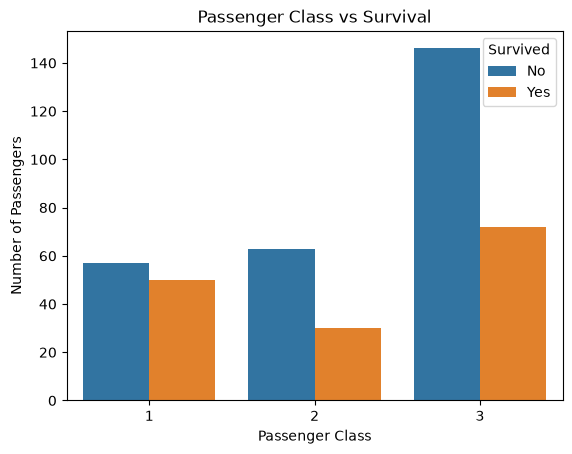

In [133]:
sns.countplot(data=df, x="Pclass", hue="Survived")

plt.title("Passenger Class vs Survival")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

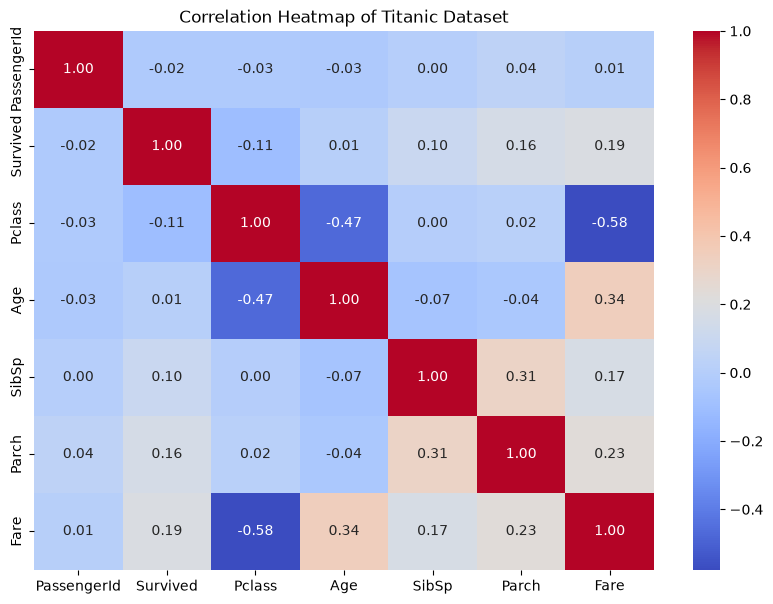

In [134]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.show()

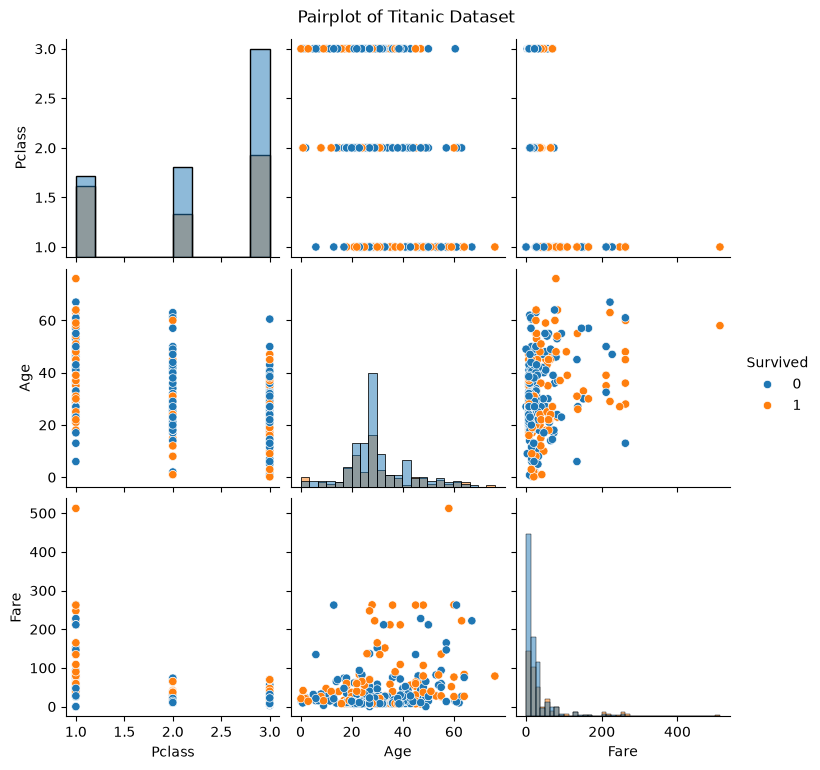

In [135]:
sns.pairplot(
    df[["Survived", "Pclass", "Age", "Fare"]],
    hue="Survived",
    diag_kind="hist"
)

plt.suptitle(
    "Pairplot of Titanic Dataset",
    y=1.02
)

plt.show()

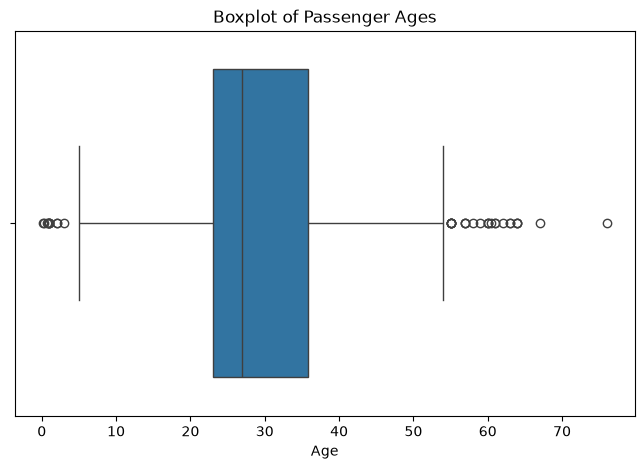

In [136]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Age")

plt.title("Boxplot of Passenger Ages")
plt.xlabel("Age")

plt.show()

In [137]:
print("FINAL EDA SUMMARY")
print("-" * 40)

print("1. Total Passengers:", len(df))

print("\n2. Missing Values:")
print(df.isnull().sum().sum())

print("\n3. Duplicate Rows:")
print(df.duplicated().sum())

print("\n4. Survival Count:")
print(df["Survived"].value_counts())

print("\n5. Survival Percentage:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))

print("\n6. Average Age:")
print(round(df["Age"].mean(), 2))

print("\n7. Average Fare:")
print(round(df["Fare"].mean(), 2))

print("\n8. Survival by Gender:")
print(df.groupby("Sex")["Survived"].mean().round(2))

print("\n9. Survival by Passenger Class:")
print(df.groupby("Pclass")["Survived"].mean().round(2))

FINAL EDA SUMMARY
----------------------------------------
1. Total Passengers: 418

2. Missing Values:
0

3. Duplicate Rows:
0

4. Survival Count:
Survived
0    266
1    152
Name: count, dtype: int64

5. Survival Percentage:
Survived
0    63.64
1    36.36
Name: proportion, dtype: float64

6. Average Age:
29.6

7. Average Fare:
35.58

8. Survival by Gender:
Sex
female    1.0
male      0.0
Name: Survived, dtype: float64

9. Survival by Passenger Class:
Pclass
1    0.47
2    0.32
3    0.33
Name: Survived, dtype: float64
